In [2]:
!pip install opencv-python matplotlib pyyaml ultralytics kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("farzadnekouei/pothole-image-segmentation-dataset")

print("Path to dataset files:", path)

In [ ]:
import ultralytics
from ultralytics import YOLO
import torch
import yaml
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# for loading images from kaggle
import kagglehub
# Download latest version
path = kagglehub.dataset_download("farzadnekouei/pothole-image-segmentation-dataset")

print("Path to dataset files:", path)

dataset_path = Path(path)

# checkinhg if yaml file is there
yaml_files = list(dataset_path.rglob("data.yaml"))
if not yaml_files:
    yaml_files = list(dataset_path.rglob("*.yaml"))

if yaml_files:
    data_yaml_path = yaml_files[0]
    print("Found YAML configuration at:", data_yaml_path)
else:
    raise FileNotFoundError(f"Could not find data.yaml or any configuration YAML inside {dataset_path}")

model = YOLO("yolov8s-seg.pt")

results = model.train(
    data=str(data_yaml_path),
    epochs=100,
    imgsz=640,
    batch=16,
    patience=15,
)

Using Colab cache for faster access to the 'pothole-image-segmentation-dataset' dataset.
Path to dataset files: /kaggle/input/pothole-image-segmentation-dataset
Found YAML configuration at: /kaggle/input/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/data.yaml
Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/pothole-image-segmentation-dataset/Pothole_Segmentation_YOLOv8/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flip

In [ ]:
from google.colab import files

# Download the best model weights from your latest training run
files.download("runs/segment/train-3/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
--- Step 1: Upload your 'best.pt' model file ---


Saving yolov8s41ep.pt to yolov8s41ep.pt

--- Step 2: Upload your test image ---


Saving 5.jpeg to 5.jpeg

Loading model from 'yolov8s41ep.pt' and running inference on '5.jpeg'...

image 1/1 /content/5.jpeg: 576x640 (no detections), 978.4ms
Speed: 20.8ms preprocess, 978.4ms inference, 7.4ms postprocess per image at shape (1, 3, 576, 640)
Results saved to /content/runs/segment/predict


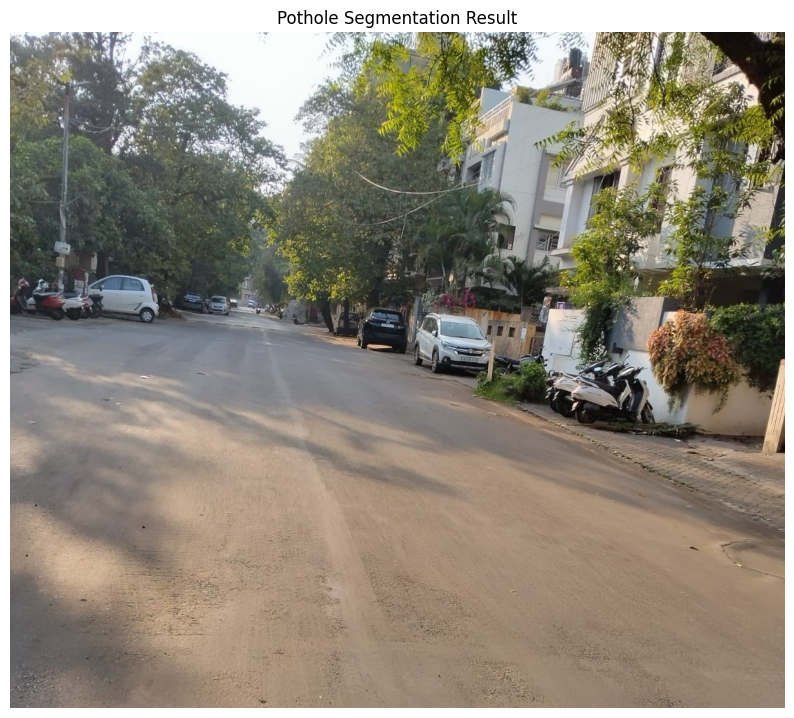

Inference complete! Output saved to: runs/segment/predict/5.jpg


In [3]:
from google.colab import files
from ultralytics import YOLO
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

print("--- Step 1: Upload your 'best.pt' model file ---")
model_uploaded = files.upload()
model_filename = list(model_uploaded.keys())[0]

print("\n--- Step 2: Upload your test image ---")
image_uploaded = files.upload()
image_filename = list(image_uploaded.keys())[0]

print(f"\nLoading model from '{model_filename}' and running inference on '{image_filename}'...")

# 1. Load the uploaded model
model = YOLO(model_filename)

# 2. Run prediction on the uploaded image
results = model(image_filename, save=True, conf=0.25)

# 3. Automatically find and display the output result
predict_folder = sorted(Path("runs/segment").glob("predict*"))[-1]
output_image_path = list(predict_folder.glob("*"))[0]

img = cv2.imread(str(output_image_path))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(img_rgb)
plt.axis('off')
plt.title("Pothole Segmentation Result")
plt.show()

print(f"Inference complete! Output saved to: {output_image_path}")

In [4]:
from google.colab import files
from ultralytics import YOLO
from pathlib import Path
import shutil
import os

print("--- Step 1: Upload your 'best.pt' model file ---")
model_uploaded = files.upload()
model_path = list(model_uploaded.keys())[0]

print("\n--- Step 2: Upload a ZIP folder containing your test images ---")
print("(Tip: Zip your folder of images on your computer first, then upload that .zip file here)")
zip_uploaded = files.upload()
zip_filename = list(zip_uploaded.keys())[0]

# Extract the uploaded zip file
extracted_dir = "images"
os.makedirs(extracted_dir, exist_ok=True)
shutil.unpack_archive(zip_filename, extracted_dir)

print(f"\nLoading model from '{model_path}' and running batch inference...")

# 1. Load your trained YOLO model
model = YOLO(model_path)

# 2. Run prediction on the entire folder of extracted images
# save=True stores results inside runs/segment/predict/
results = model(extracted_dir, save=True, conf=0.25)

# 3. Locate the latest prediction folder generated by YOLO
predict_folder = sorted(Path("runs/segment").glob("predict*"))[-1]
print(f"Inference complete! Results saved in: {predict_folder}")

# 4. Zip up the prediction results folder for easy downloading
output_zip_name = "pothole_segmentation_results.zip"
shutil.make_archive(output_zip_name.replace('.zip', ''), 'zip', predict_folder)

print(f"\n--- Step 3: Automatically downloading '{output_zip_name}' to your computer ---")

# 5. Trigger automatic browser download
files.download(output_zip_name)

--- Step 1: Upload your 'best.pt' model file ---


Saving yolov8s41ep.pt to yolov8s41ep (1).pt

--- Step 2: Upload a ZIP folder containing your test images ---
(Tip: Zip your folder of images on your computer first, then upload that .zip file here)


Saving images.zip to images.zip

Loading model from 'yolov8s41ep (1).pt' and running batch inference...



FileNotFoundError: No images or videos found in images. Supported formats are:
images: {'dng', 'tiff', 'jpeg', 'jpg', 'avif', 'heic', 'webp', 'mpo', 'png', 'tif', 'jp2', 'heif', 'bmp'}
videos: {'gif', 'wmv', 'mov', 'ts', 'mp4', 'webm', 'avi', 'mpg', 'asf', 'mkv', 'm4v', 'mpeg'}